# Aim :To Perform and Analysis of Support Vector Machine (SVM)

In [1]:
# Name: Sanika Vijay Kale
# Roll No.: 23
# Branch: B.E. CSE (Data Science)
# Year: Final Year
# Semester: VII
# Academic Year: 2026-27

Libraries imported successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

print("Libraries imported successfully!")

In [2]:
data = load_iris()

X = data.data[:, 2:4]  # Petal length and petal width
y = data.target

print("Dataset loaded successfully!")
print("Total records:", X.shape[0])
print("Input features:", data.feature_names[2:4])
print("Flower classes:", data.target_names)

Dataset loaded successfully!
Total records: 150
Input features: ['petal length (cm)', 'petal width (cm)']
Flower classes: ['setosa' 'versicolor' 'virginica']


In [3]:
df = pd.DataFrame(
    X,
    columns=["Petal Length", "Petal Width"]
)

df["Flower Class"] = [data.target_names[i] for i in y]

display(df.head())

,Petal Length,Petal Width,Flower Class
0,1.4,0.2,setosa
1,1.4,0.2,setosa
2,1.3,0.2,setosa
3,1.5,0.2,setosa
4,1.4,0.2,setosa


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [5]:
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

print("SVM model created successfully!")

SVM model created successfully!


In [6]:
model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [7]:
y_pred = model.predict(X_test)

print("Actual values:   ", y_test[:10])
print("Predicted values:", y_pred[:10])

Actual values:    [0 2 1 1 0 1 0 0 2 1]
Predicted values: [0 2 1 1 0 1 0 0 2 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", round(accuracy * 100, 2), "%")

SVM Accuracy: 93.33 %


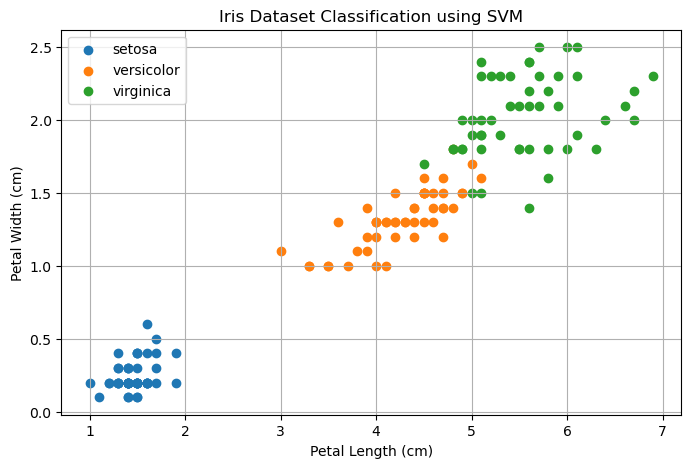

In [9]:
plt.figure(figsize=(8, 5))

for i, name in enumerate(data.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=name
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset Classification using SVM")
plt.legend()
plt.grid()
plt.show()

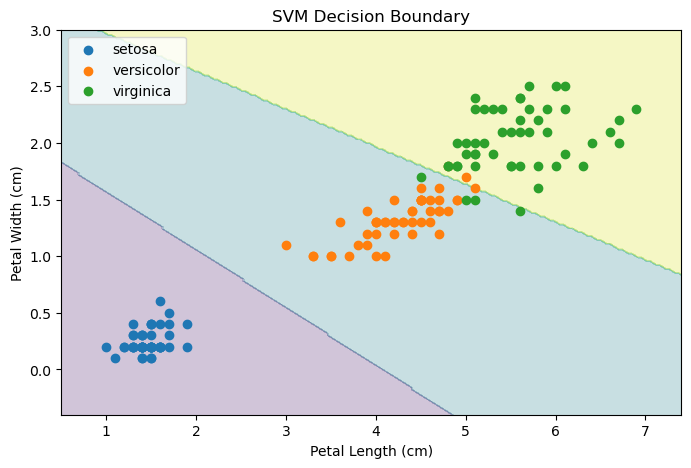

In [10]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.25)

for i, name in enumerate(data.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=name
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("SVM Decision Boundary")
plt.legend()
plt.show()

In [11]:
print("RESULT")
print("SVM algorithm implemented successfully.")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Kernel used: Linear")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

RESULT
SVM algorithm implemented successfully.
Accuracy: 93.33 %
Kernel used: Linear
Training records: 120
Testing records: 30
